# Model training

Trains ResNet18 on the regular and augmented conditions (5 seeds each). Results are saved to `results/`.

**v2 changes** (v1 results are kept in `results/v1/`):
- label smoothing, because v1 became overconfident
- smaller learning rate for the pretrained layers, because v1 memorised the training set by step ~100
- augmentation applied on the fly instead of one saved copy per image

In [1]:
#Imports
import copy
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

In [2]:
#Settings
SEEDS = [0, 1, 2, 3, 4] #5 runs per condition
CONDITIONS = ["regular", "augmented"]

BATCH_SIZE = 32
HEAD_LR = 1e-4 #new output layer
BACKBONE_LR = 1e-5 #pretrained layers, 10x smaller so they don't lose what they learned on ImageNet
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1 #aim for 90% sure instead of 100%

MAX_STEPS = 600 #same number of updates for both conditions
EVAL_EVERY = 50 #check validation every 50 steps
PATIENCE = 4 #stop after 4 checks without improvement

NUM_WORKERS = 4
torch.set_num_threads(os.cpu_count())

In [3]:
# Paths
PROJECT_DIR = Path.cwd()

data_path = PROJECT_DIR / "processed_data"
results_path = PROJECT_DIR / "results"
models_path = PROJECT_DIR / "models"

assert data_path.exists(), (
    f"Processed data not found at: {data_path}. Run preprocessing.ipynb first."
)

results_path.mkdir(exist_ok=True)
models_path.mkdir(exist_ok=True)

print("Data:", data_path.relative_to(PROJECT_DIR))
print("Results:", results_path.relative_to(PROJECT_DIR))
print("Models:", models_path.relative_to(PROJECT_DIR))

Data: processed_data
Results: results
Models: models


In [4]:
#Load data
#Convert to tensors and normalise with ImageNet stats
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#Same augmentation settings as preprocessing.ipynb, but applied while training.
#v1 used one saved augmented copy per image, which the model could memorise like any other image.
#Now every time an image is loaded it gets a new random flip/rotation/colour change
augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomRotation(20)], p=0.8),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05)
    ], p=0.8),
    transforms.RandomApply([
        transforms.RandomAffine(degrees=0, translate=(0.03, 0.03))
    ], p=0.5),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.2)
])


def load_split(split):
    return datasets.ImageFolder(
        root=data_path / "regular" / split,
        transform=transform
    )


def load_train(condition):
    #Both conditions use the same original training images,
    #the augmented one just edits them randomly as they're loaded
    if condition == "augmented":
        train_transform = transforms.Compose([augment, transform])
    else:
        train_transform = transform

    return datasets.ImageFolder(
        root=data_path / "regular" / "train",
        transform=train_transform
    )


#Val and test are never augmented
val_dataset = load_split("val")
test_dataset = load_split("test")

classes = test_dataset.classes

print("Classes:", classes)
print("Train:", len(load_train("regular")))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['jerry', 'tom', 'tom_jerry_0', 'tom_jerry_1']
Train: 1369
Validation: 1370
Test: 2739


In [5]:
#Model
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def build_model():
    #Pretrained ResNet18 with a new 4-class output layer
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(classes))
    return model


def build_optimizer(model):
    #Pretrained layers get a smaller learning rate than the new output layer.
    #In v1 everything used 1e-4 and training loss was ~0 by step 100, so it was memorising
    head = list(model.fc.parameters())
    backbone = [p for name, p in model.named_parameters() if not name.startswith("fc.")]

    def groups(params, lr):
        #No weight decay on biases and BatchNorm
        return [
            {"params": [p for p in params if p.ndim > 1], "lr": lr, "weight_decay": WEIGHT_DECAY},
            {"params": [p for p in params if p.ndim <= 1], "lr": lr, "weight_decay": 0.0}
        ]

    return torch.optim.AdamW(groups(backbone, BACKBONE_LR) + groups(head, HEAD_LR))


#Label smoothing for training. In v1 val loss kept going up while val accuracy stayed flat,
#meaning the model was getting more confident, not more correct
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

#Plain cross-entropy for reporting, so v1 and v2 losses can be compared
eval_criterion = nn.CrossEntropyLoss()

In [6]:
#Evaluation
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probs = []

    for images, labels in loader:
        logits = model(images)
        total_loss += eval_criterion(logits, labels).item() * len(labels)
        all_labels.append(labels)
        all_probs.append(torch.softmax(logits, dim=1))

    labels = torch.cat(all_labels)
    probs = torch.cat(all_probs)
    accuracy = (probs.argmax(dim=1) == labels).float().mean().item()

    return total_loss / len(labels), accuracy, labels, probs

In [7]:
#Training
def train_one_run(condition, seed):

    set_seed(seed)

    train_loader = DataLoader(
        load_train(condition),
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=64,
        num_workers=NUM_WORKERS
    )

    model = build_model()
    optimizer = build_optimizer(model)

    history = []
    best_val_loss = float("inf")
    best_state = None
    best_step = 0
    checks_without_improvement = 0

    step = 0
    running_loss = 0.0
    batches = iter(train_loader)

    while step < MAX_STEPS:

        #Restart the training set when it runs out
        try:
            images, labels = next(batches)
        except StopIteration:
            batches = iter(train_loader)
            images, labels = next(batches)

        model.train()
        loss = criterion(model(images), labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        step += 1
        running_loss += loss.item()

        if step % EVAL_EVERY == 0:

            val_loss, val_accuracy, _, _ = evaluate(model, val_loader)

            history.append({
                "step": step,
                "train_loss": running_loss / EVAL_EVERY,
                "val_loss": val_loss,
                "val_accuracy": val_accuracy
            })
            running_loss = 0.0

            print(
                f"  step {step:4d} | "
                f"train loss {history[-1]['train_loss']:.3f} | "
                f"val loss {val_loss:.3f} | "
                f"val acc {val_accuracy:.3f}"
            )

            #Keep the checkpoint with the lowest validation loss
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                best_step = step
                checks_without_improvement = 0
            else:
                checks_without_improvement += 1

                if checks_without_improvement >= PATIENCE:
                    print(f"  Early stopping at step {step}")
                    break

    model.load_state_dict(best_state)

    return model, history, best_step, best_val_loss

In [8]:
#Save configuration
config = {
    "version": "v2",
    "model": "resnet18, ImageNet pretrained (IMAGENET1K_V1), new 4-class output layer",
    "fine_tuning": "all layers",
    "loss": f"cross-entropy with label smoothing {LABEL_SMOOTHING} for training, plain cross-entropy for reporting",
    "optimiser": "AdamW, no weight decay on biases and BatchNorm",
    "head_learning_rate": HEAD_LR,
    "backbone_learning_rate": BACKBONE_LR,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "max_steps": MAX_STEPS,
    "eval_every": EVAL_EVERY,
    "patience": PATIENCE,
    "checkpoint": "lowest validation loss",
    "seeds": SEEDS,
    "conditions": CONDITIONS,
    "augmentation": "on the fly, training images only: " + str(augment),
    "classes": classes,
    "normalisation": "ImageNet mean and std",
    "data": {
        "source": "processed_data/regular from preprocessing.ipynb (seed 42, temporal 25/25/50 split)",
        "train_images": len(load_train("regular")),
        "val_images": len(val_dataset),
        "test_images": len(test_dataset)
    },
    "parameters": sum(p.numel() for p in build_model().parameters()),
    "hardware": "CPU only (12 cores, 14GB RAM)",
    "torch_version": torch.__version__
}

(results_path / "config.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "version": "v2",
  "model": "resnet18, ImageNet pretrained (IMAGENET1K_V1), new 4-class output layer",
  "fine_tuning": "all layers",
  "loss": "cross-entropy with label smoothing 0.1 for training, plain cross-entropy for reporting",
  "optimiser": "AdamW, no weight decay on biases and BatchNorm",
  "head_learning_rate": 0.0001,
  "backbone_learning_rate": 1e-05,
  "weight_decay": 0.0001,
  "batch_size": 32,
  "max_steps": 600,
  "eval_every": 50,
  "patience": 4,
  "checkpoint": "lowest validation loss",
  "seeds": [
    0,
    1,
    2,
    3,
    4
  ],
  "conditions": [
    "regular",
    "augmented"
  ],
  "augmentation": "on the fly, training images only: Compose(\n    RandomHorizontalFlip(p=0.5)\n    RandomApply(\n    p=0.8\n    RandomRotation(degrees=[-20.0, 20.0], interpolation=nearest, expand=False, fill=0)\n)\n    RandomApply(\n    p=0.8\n    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.7, 1.3), hue=(-0.05, 0.05))\n)\n    RandomApply(\n    p=0.5\

In [9]:
#Run all experiments
#Test set is used once per run, after training
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    num_workers=NUM_WORKERS
)

for condition in CONDITIONS:

    for seed in SEEDS:

        run_name = f"{condition}_seed{seed}"
        result_file = results_path / f"{run_name}.json"

        if result_file.exists():
            print(f"Skipping {run_name}: already done")
            continue

        print(f"\nTraining {run_name}")
        start = time.time()

        model, history, best_step, best_val_loss = train_one_run(condition, seed)

        test_loss, test_accuracy, labels, probs = evaluate(model, test_loader)
        predicted = probs.argmax(dim=1)

        torch.save(model.state_dict(), models_path / f"{run_name}.pt")

        #Save test predictions for evaluation
        predictions = pd.DataFrame(
            probs.numpy(),
            columns=[f"prob_{c}" for c in classes]
        )
        predictions.insert(0, "image", [
            str(Path(path).relative_to(PROJECT_DIR)) for path, _ in test_dataset.samples
        ])
        predictions.insert(1, "label", [classes[i] for i in labels])
        predictions.insert(2, "predicted", [classes[i] for i in predicted])
        predictions.to_csv(
            results_path / f"{run_name}_test_predictions.csv",
            index=False
        )

        result = {
            "condition": condition,
            "seed": seed,
            "best_step": best_step,
            "best_val_loss": best_val_loss,
            "test_loss": test_loss,
            "test_accuracy": test_accuracy,
            "minutes": (time.time() - start) / 60,
            "history": history
        }
        result_file.write_text(json.dumps(result, indent=2))

        print(
            f"Done {run_name}: test acc {test_accuracy:.3f}, "
            f"test loss {test_loss:.3f}, {result['minutes']:.1f} min"
        )

Skipping regular_seed0: already done
Skipping regular_seed1: already done

Training regular_seed2
  step   50 | train loss 1.164 | val loss 1.245 | val acc 0.478
  step  100 | train loss 0.785 | val loss 1.214 | val acc 0.499
  step  150 | train loss 0.625 | val loss 1.161 | val acc 0.528
  step  200 | train loss 0.532 | val loss 1.213 | val acc 0.509
  step  250 | train loss 0.486 | val loss 1.201 | val acc 0.526
  step  300 | train loss 0.449 | val loss 1.184 | val acc 0.531
  step  350 | train loss 0.428 | val loss 1.215 | val acc 0.518
  Early stopping at step 350
Done regular_seed2: test acc 0.514, test loss 1.164, 27.5 min

Training regular_seed3
  step   50 | train loss 1.162 | val loss 1.268 | val acc 0.432
  step  100 | train loss 0.808 | val loss 1.229 | val acc 0.486
  step  150 | train loss 0.632 | val loss 1.147 | val acc 0.537
  step  200 | train loss 0.549 | val loss 1.154 | val acc 0.527
  step  250 | train loss 0.488 | val loss 1.122 | val acc 0.560
  step  300 | train

In [10]:
#Summary
runs = pd.DataFrame([
    json.loads((results_path / f"{c}_seed{s}.json").read_text())
    for c in CONDITIONS
    for s in SEEDS
]).drop(columns="history")

print(runs[["condition", "seed", "best_step", "test_accuracy", "test_loss"]])

summary = runs.groupby("condition", sort=False)[["test_accuracy", "test_loss"]].agg(["mean", "std"])
summary.to_csv(results_path / "summary.csv")

print("\nMean and standard deviation over seeds")
print(summary)

   condition  seed  best_step  test_accuracy  test_loss
0    regular     0        300       0.536327   1.189915
1    regular     1        200       0.565170   1.046350
2    regular     2        150       0.514421   1.164192
3    regular     3        450       0.575027   1.092343
4    regular     4        600       0.548375   1.134579
5  augmented     0        500       0.613363   1.024440
6  augmented     1        350       0.606061   0.965982
7  augmented     2        600       0.593647   0.990405
8  augmented     3        450       0.597663   1.084891
9  augmented     4        500       0.590727   1.065663

Mean and standard deviation over seeds
          test_accuracy           test_loss          
                   mean       std      mean       std
condition                                            
regular        0.547864  0.023922  1.125476  0.057212
augmented      0.600292  0.009310  1.026276  0.049781


In [11]:
#Ensemble: average the 5 seeds' predictions for each test image.
#Each seed makes slightly different mistakes, so averaging cancels some of them out
prob_columns = [f"prob_{c}" for c in classes]
ensemble = {}

for condition in CONDITIONS:
    seed_predictions = [
        pd.read_csv(results_path / f"{condition}_seed{seed}_test_predictions.csv")
        for seed in SEEDS
    ]
    probs = np.mean([p[prob_columns].values for p in seed_predictions], axis=0)
    labels = seed_predictions[0]["label"].map(classes.index).values

    ensemble[condition] = {
        "test_accuracy": (probs.argmax(axis=1) == labels).mean(),
        "test_loss": -np.log(probs[np.arange(len(labels)), labels]).mean()
    }

ensemble = pd.DataFrame(ensemble).T
ensemble.to_csv(results_path / "ensemble.csv")

print("5-seed ensemble")
print(ensemble.round(3))

5-seed ensemble
           test_accuracy  test_loss
regular            0.558      1.064
augmented          0.608      0.973


In [12]:
#v1 vs v2 (mean over seeds)
v1 = pd.read_csv(results_path / "v1" / "summary.csv", header=[0, 1], index_col=0).dropna()

comparison = pd.DataFrame({
    "v1 accuracy": v1[("test_accuracy", "mean")],
    "v2 accuracy": summary[("test_accuracy", "mean")],
    "v1 loss": v1[("test_loss", "mean")],
    "v2 loss": summary[("test_loss", "mean")]
})

print(comparison.round(3))

           v1 accuracy  v2 accuracy  v1 loss  v2 loss
condition                                            
regular          0.595        0.548    1.238    1.125
augmented        0.598        0.600    1.293    1.026


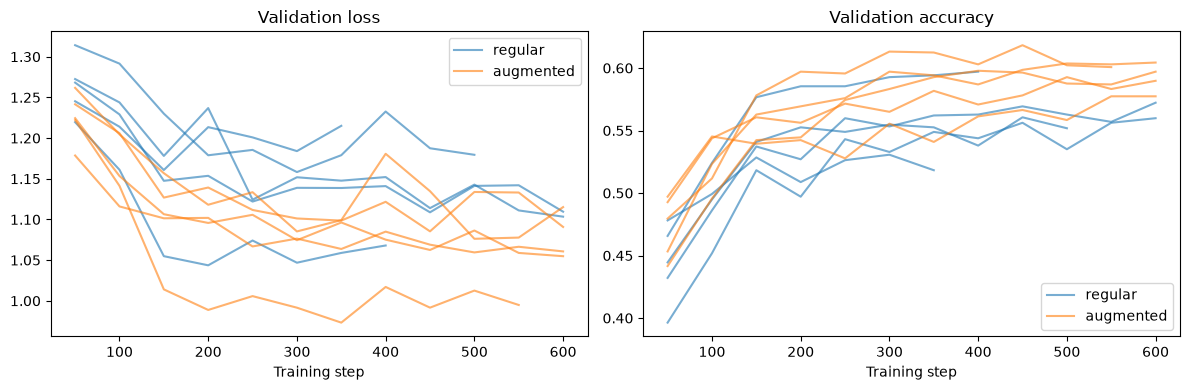

In [13]:
#Validation curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for condition, colour in zip(CONDITIONS, ["tab:blue", "tab:orange"]):
    for seed in SEEDS:
        history = pd.DataFrame(
            json.loads((results_path / f"{condition}_seed{seed}.json").read_text())["history"]
        )
        label = condition if seed == SEEDS[0] else None
        axes[0].plot(history["step"], history["val_loss"], color=colour, alpha=0.6, label=label)
        axes[1].plot(history["step"], history["val_accuracy"], color=colour, alpha=0.6, label=label)

axes[0].set_title("Validation loss")
axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Training step")
    ax.legend()

plt.tight_layout()
plt.show()

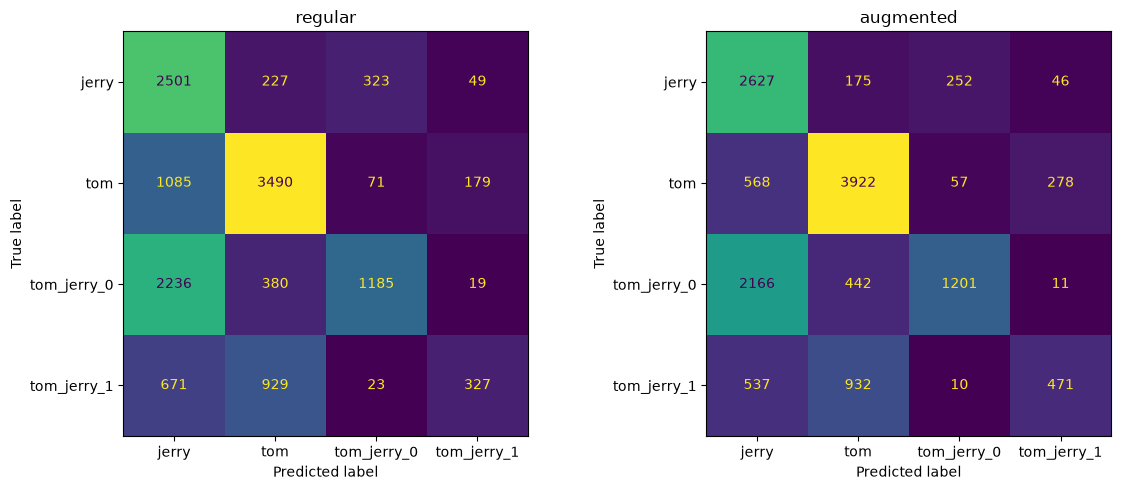

In [14]:
#Confusion matrices (test set, all seeds combined)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, condition in zip(axes, CONDITIONS):

    predictions = pd.concat([
        pd.read_csv(results_path / f"{condition}_seed{seed}_test_predictions.csv")
        for seed in SEEDS
    ])

    matrix = confusion_matrix(
        predictions["label"],
        predictions["predicted"],
        labels=classes
    )

    ConfusionMatrixDisplay(matrix, display_labels=classes).plot(ax=ax, colorbar=False)
    ax.set_title(condition)

plt.tight_layout()
plt.show()